# Random forest vs. hedonic OLS: art auction prices

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ajavakhishvili16/apma-project/blob/main/random_forest_analysis/rf_vs_ols_colab.ipynb)

**To run:** Runtime → Run all (about 4 minutes). For the live demo only: run cell 1 (section 1), then the last cell.

APMA 4903 project. This notebook runs the random forest part of our analysis:

1. Fit the hedonic model by OLS on 21,783 training sales (Nov 2023 – Dec 2025).
2. Tune and fit a random forest (500 trees) on the same sales and the same seven characteristics.
3. Compare both on 8,458 sales from 2026 that neither model has seen.
4. Run our own from-scratch random forest (the pseudocode on the slides, line by line) and check it against scikit-learn.

**How to run:** choose **Runtime → Run all**. Nothing to upload: the first cell downloads the project from GitHub. The whole notebook takes about 5 minutes.

## 1. Get the code and data

In [1]:
import os, sys
# Get the code and data. The analysis lives in apma-project/random_forest_analysis/,
# the two data files in the repository root (one folder up).
if os.path.exists('src/random_forest.py'):                       # already in random_forest_analysis/
    pass
elif os.path.exists('random_forest_analysis/src/random_forest.py'):  # in the repository root
    os.chdir('random_forest_analysis')
else:                                                            # e.g. a fresh Colab session
    if os.path.exists('apma-project'):
        !git -C apma-project pull -q
    else:
        !git clone -q https://github.com/ajavakhishvili16/apma-project.git
    os.chdir('apma-project/random_forest_analysis')
sys.path.insert(0, 'src')
print('Working in', os.getcwd())
print('Training data found:', os.path.exists('../training_set_2023_2025_clean-2.csv'))
print('Test data found:    ', os.path.exists('../test_set_2026_clean-2.csv'))

Working in /content/apma-project/random_forest_analysis
Training data found: True
Test data found:     True


## 2. Hedonic model (OLS)

ln(P/A) on exposure, fame, ln A, (ln A)², medium, support, sale season and creation period; standard errors clustered by artist.

In [2]:
!python src/hedonic_ols.py

n = 21783, parameters = 25, R^2 = 0.3766
                             coef  se_cluster       p  pct_effect_kennedy
Intercept                 11.8785      0.4676  0.0000                 NaN
exposure: circulating      0.6714      0.0644  0.0000             95.2971
exposure: established      0.8369      0.1185  0.0000            129.3068
exposure: local            0.4333      0.0464  0.0000             54.0661
medium_c: acrylic         -0.0273      0.0775  0.7250             -2.9822
medium_c: drawing         -0.7267      0.0796  0.0000            -51.8035
medium_c: ink             -0.2024      0.1048  0.0534            -18.7729
medium_c: mixed           -0.4023      0.1520  0.0081            -33.8887
medium_c: other           -1.0299      0.0808  0.0000            -64.4125
medium_c: watercolour      0.1657      0.0934  0.0760             17.5052
support_c: other          -0.6254      0.0796  0.0000            -46.6631
support_c: panel          -0.1113      0.0530  0.0358            -10.65

## 3. Random forest: tune, fit, and compare on 2026 sales

Takes about a minute. Settings are tuned on training data only (fit to June 2025, validate on July–December 2025).

In [3]:
!python src/random_forest.py

training sales: 21783 (Nov 2023 - Dec 2025)
test sales:     8458 (Jan 2026 - Oct 2026)



Tuning the forest inside the training set:


  leaf  1, max_features 0.33: validation R^2 0.3729


  leaf  1, max_features 0.5 : validation R^2 0.3804


  leaf  1, max_features 1.0 : validation R^2 0.3740


  leaf  5, max_features 0.33: validation R^2 0.4256


... (8 outputs left out)

  leaf 40, max_features 0.33: validation R^2 0.4022


  leaf 40, max_features 0.5 : validation R^2 0.4065


  leaf 40, max_features 1.0 : validation R^2 0.3984



Accuracy on the 2026 test set:
                  R2  RMSE_log  MAE_log  typical_miss_factor  share_within_1.5x
predict_mean  -0.003     1.821    1.440                3.343              0.177
hedonic_ols    0.380     1.432    1.115                2.483              0.241
random_forest  0.438     1.364    1.067                2.398              0.248

R^2 gain of the forest: 0.057 (95% bootstrap interval 0.047 to 0.067)
Training R^2: OLS 0.377, forest 0.619

Permutation importance (rise in test MSE):
                random_forest  hedonic_ols
fame                    0.440        0.103
area                    1.788        1.995
exposure                0.419        0.239
medium_c                0.411        0.248
support_c               0.202        0.140
season                  0.074        0.107
created_period          0.151        0.103

wrote results to /content/apma-project/random_forest_analysis/results


## 4. Results table

In [4]:
import json, pandas as pd
r = json.load(open('results/rf_vs_ols_metrics.json'))
t = pd.DataFrame(r['test']).T.rename(index={'predict_mean':'Baseline: training mean','hedonic_ols':'Hedonic OLS','random_forest':'Random forest'})
t.columns = ['R²','RMSE (log)','MAE (log)','Median error factor','Share within 1.5×']
display(t.round(3))
lo, hi = r['R2_gain_95ci_bootstrap']
print(f"Forest R² gain: {r['R2_gain']:.3f}  (95% bootstrap interval {lo:.3f} to {hi:.3f})")
print(f"Training R²: OLS {r['train']['hedonic_ols']['R2']:.3f}, forest {r['train']['random_forest']['R2']:.3f}")
print('Forest settings:', r['forest_settings'])

,R²,RMSE (log),MAE (log),Median error factor,Share within 1.5×
Baseline: training mean,-0.003,1.821,1.440,3.343,0.177
Hedonic OLS,0.380,1.432,1.115,2.483,0.241
Random forest,0.438,1.364,1.067,2.398,0.248


Forest R² gain: 0.057  (95% bootstrap interval 0.047 to 0.067)
Training R²: OLS 0.377, forest 0.619
Forest settings: {'trees': 500, 'min_samples_leaf': 5, 'max_features': 0.33, 'inputs': 28}


## 5. What the forest learned: size and fame

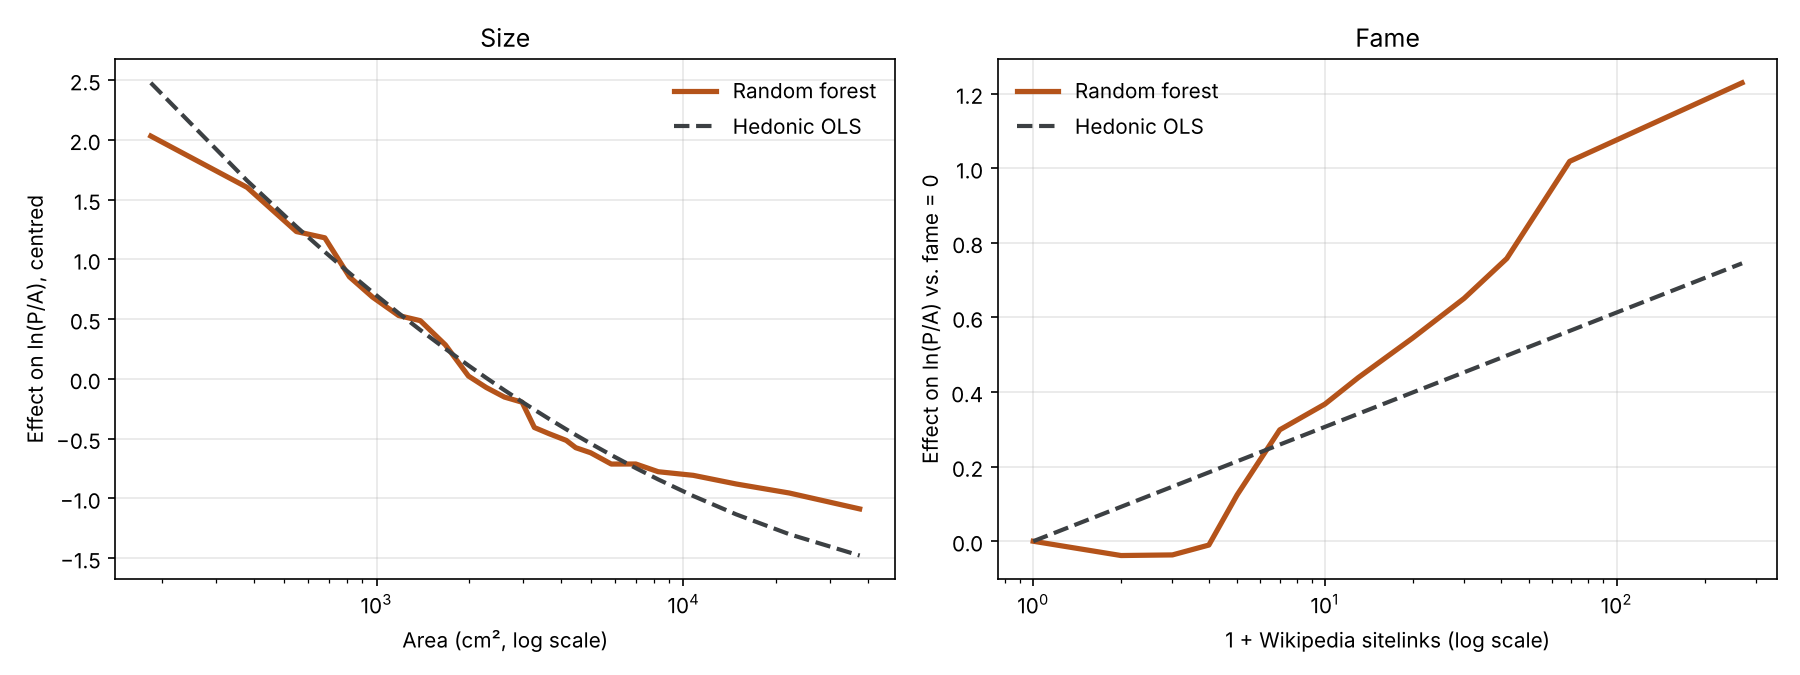

In [5]:
from IPython.display import Image
Image('results/rf_partial_dependence.png')

## 6. Validation: how B, m and the leaf size were chosen

Uses only the training sales: fit on sales before July 2025, score on July–December 2025.
Left: validation R² against the minimum leaf size, one line per m. Right: validation R² as trees are added.

m                    9      14     28
min_samples_leaf                     
1                 0.373  0.380  0.374
5                 0.426  0.423  0.409
10                0.425  0.424  0.415
20                0.416  0.417  0.411
40                0.402  0.407  0.398

chosen: m = 9, min leaf = 5, validation R^2 = 0.4256
B =    1: validation R^2 0.1982
B =    5: validation R^2 0.3683
B =   10: validation R^2 0.4000
B =   50: validation R^2 0.4225
B =  100: validation R^2 0.4239
B =  250: validation R^2 0.4252
B =  500: validation R^2 0.4271
B = 1000: validation R^2 0.4277

wrote /content/apma-project/random_forest_analysis/results/validation_curves.png


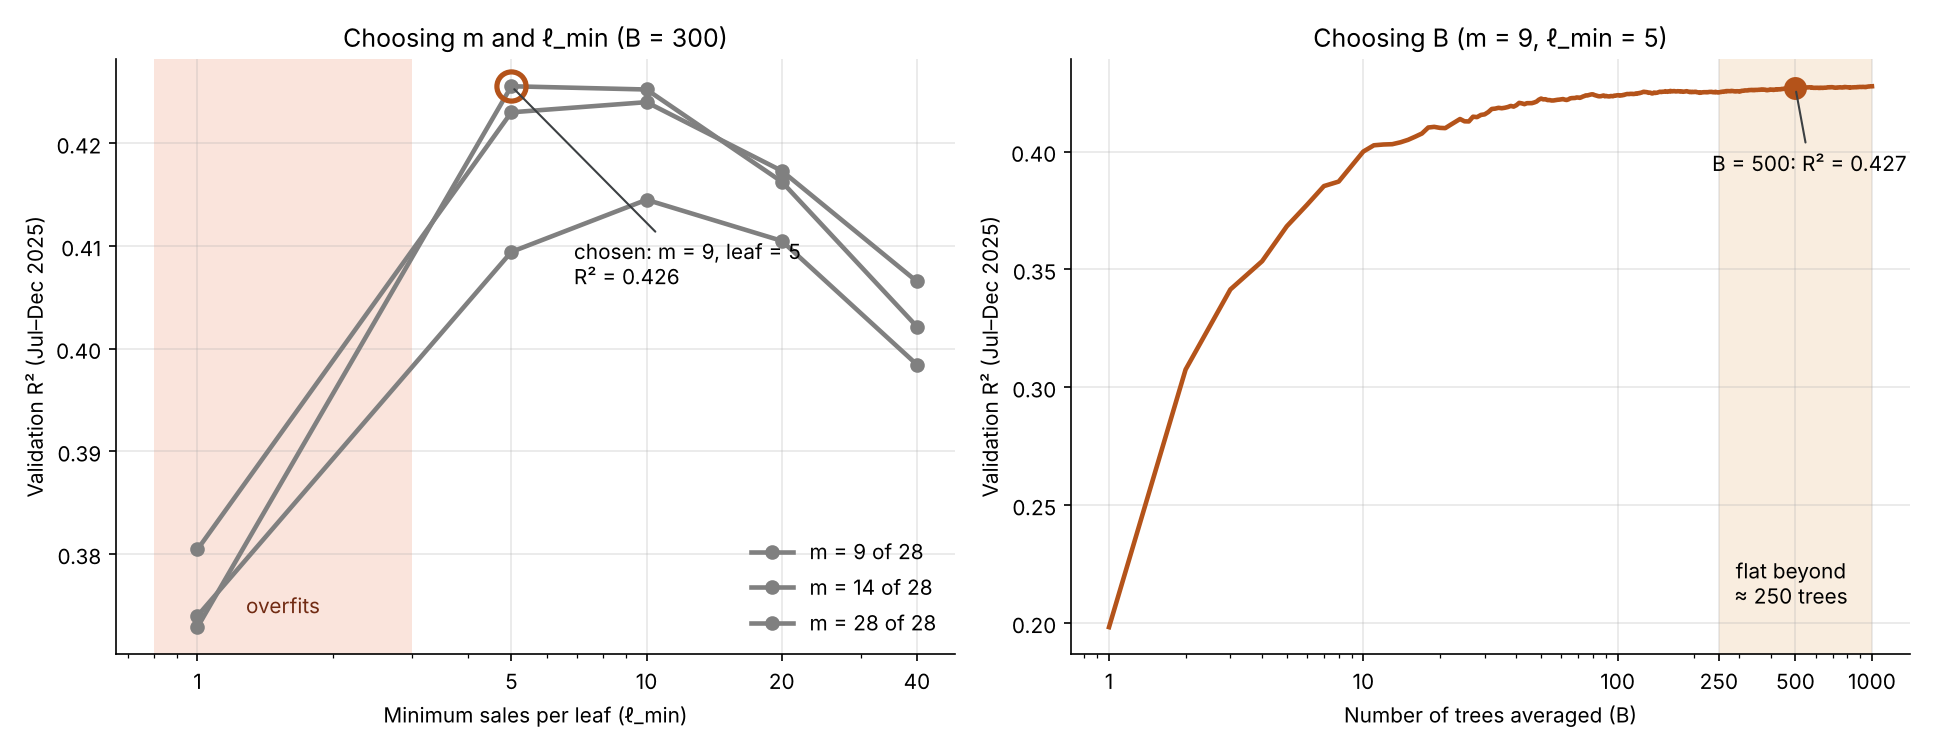

In [6]:
!python src/validation.py
from IPython.display import Image
Image('results/validation_curves.png')

## 7. Averaging trees on the 2026 test set

The same averaging effect on the held-out 2026 sales (Part 4, aggregation).

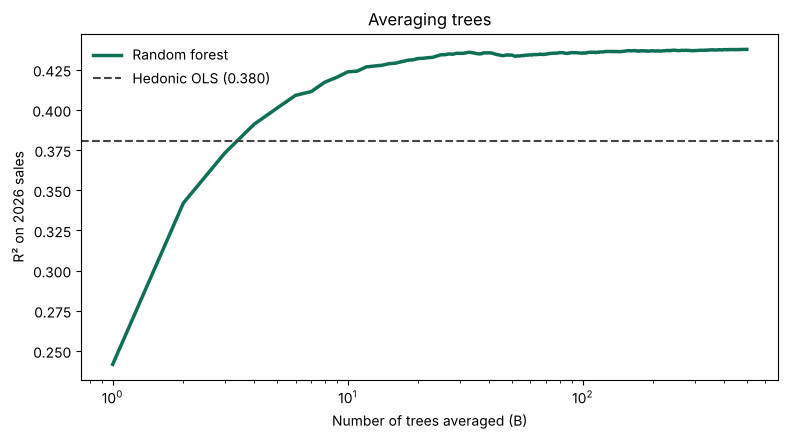

B =   1: R² 0.242
B =  10: R² 0.424
B = 100: R² 0.435
B = 500: R² 0.438


In [7]:
import sys, numpy as np, matplotlib.pyplot as plt
sys.path.insert(0, 'src')
from sklearn.ensemble import RandomForestRegressor
from common import BASE, TRAIN, TEST, load, metrics
from random_forest import forest_inputs
%matplotlib inline
train = load(TRAIN)
levels = {c: sorted(train[c].astype(str).unique()) for c in BASE}
test = load(TEST)
Xtr, Xte = forest_inputs(train, levels), forest_inputs(test, levels)
st = r['forest_settings']   # the settings chosen by validation in section 3
rf = RandomForestRegressor(st['trees'], min_samples_leaf=st['min_samples_leaf'], max_features=st['max_features'], n_jobs=-1, random_state=0).fit(Xtr, train.y)
tree_preds = np.array([t.predict(Xte.values) for t in rf.estimators_])
running = np.cumsum(tree_preds, axis=0) / np.arange(1, 501)[:, None]
r2_by_B = [metrics(test.y, running[b])['R2'] for b in range(500)]
ols_r2 = r['test']['hedonic_ols']['R2']

plt.figure(figsize=(9, 4.5))
plt.plot(range(1, 501), r2_by_B, color='#0F6E56', lw=2.5, label='Random forest')
plt.axhline(ols_r2, ls='--', color='#444441', label=f'Hedonic OLS ({ols_r2:.3f})')
plt.xscale('log'); plt.xlabel('Number of trees averaged (B)'); plt.ylabel('R² on 2026 sales')
plt.title('Averaging trees'); plt.legend(frameon=False); plt.show()
for B in [1, 10, 100, 500]:
    print(f'B = {B:>3}: R² {r2_by_B[B-1]:.3f}')

## 8. Our own implementation of the pseudocode

`random_forest.py` uses scikit-learn for speed. `forest_from_scratch.py` implements the same algorithm ourselves, block by block from the slides' pseudocode:

| Pseudocode | Function in `forest_from_scratch.py` |
|---|---|
| Algorithm 1: bootstrap each tree, average the trees | `RandomForest.fit`, `RandomForest.predict` |
| Algorithm 2: stopping rule, draw m inputs, best split, recurse | `grow_tree` |
| Algorithm 3: sort, prefix sums, gain n_L n_R / n (ȳ_L − ȳ_R)² | `best_split` |

The script checks it against scikit-learn: the best root split must match exactly, and a 50-tree forest must reach about the same 2026 R². Takes about 30–60 seconds.

In [8]:
!python src/forest_from_scratch.py

training sales n = 21783, inputs p = 28, m = 9, min leaf = 5



1. Best root split (all sales, all inputs)
   ours:         ln_area <= 7.4774, gain 12358.0553
   scikit-learn: ln_area <= 7.4774, gain 12358.0553
   difference in gain: 7.28e-12



2. 50-tree forests on the 2026 test set (ours took 32 s to grow)
   ours, B =  1: R^2 0.223
   ours, B = 10: R^2 0.414
   ours, B = 50: R^2 0.434


   scikit-learn, B = 50: R^2 0.434


   our trees: median depth 25, median leaves 2313

The two forests differ only in their random draws (and scikit-learn counts the
minimum leaf size in distinct sales rather than draws), so R^2 agrees closely, not exactly.


### Live: grow a small forest with our code

Each tree takes under a second. Watch R² on the 2026 sales rise as trees are averaged (Part 4).

In [9]:
import sys, time, numpy as np
sys.path.insert(0, 'src')
from common import BASE, TRAIN, TEST, load, metrics
from random_forest import forest_inputs
# Load the data here too, so this cell also works when run on its own
train, test = load(TRAIN), load(TEST)
levels = {c: sorted(train[c].astype(str).unique()) for c in BASE}
Xtr, Xte = forest_inputs(train, levels), forest_inputs(test, levels)

from forest_from_scratch import RandomForest, best_split
f = RandomForest(B=20, m=9, min_leaf=5, seed=1)
t0 = time.time(); f.fit(Xtr.values, train.y.values)
print(f'grew {f.B} trees in {time.time()-t0:.0f} s')
P = f.tree_predictions(Xte.values)
for b in [1, 2, 5, 10, 20]:
    print(f'B = {b:>2}: R² on 2026 sales {metrics(test.y, P[:b].mean(0))["R2"]:.3f}')

# Algorithm 3 on one input: the best area cutoff at the root
g, s = best_split(Xtr['ln_area'].values, train.y.values, 5)
print(f'best root split on area: area <= {np.exp(s):,.0f} cm², gain {g:,.0f}')

grew 20 trees in 12 s
B =  1: R² on 2026 sales 0.209
B =  2: R² on 2026 sales 0.332
B =  5: R² on 2026 sales 0.397
B = 10: R² on 2026 sales 0.416
B = 20: R² on 2026 sales 0.429
best root split on area: area <= 1,768 cm², gain 12,358
